# 02 — LSTM · Vol Regime Classification · stocks

**Job:** `J02_vol_regime` | **Phase:** P3 | **Status:** active

**Architecture:** 2-layer LSTM (64 units, dropout 0.2)

**Project path (WSL):** `~/ai-workspace/experiments/stock-prediction`

**Kernel:** select **`Python (stock-prediction)`** in the kernel picker (register with `bash scripts/install-jupyter-kernel.sh` if missing).

```bash
cd ~/ai-workspace/experiments/stock-prediction
source .venv/bin/activate
```


## 0) Run configuration

`fast_dev` = 200 symbols / 30 epochs (quick tests). `full` = entire universe / 100 epochs.

In [1]:
# --- ML Iteration 2 job config (do not rename without updating scaffold) ---
JOB_ID = "02"
JOB_SLUG = "vol_regime"
ARCHITECTURE = "lstm"
UNIVERSE = "stocks"
ASSET_TYPE = "stock"
TARGET_TYPE = "vol_regime_21"
UNIVERSE_PREFIX = "stocks_universe"
TARGET_SUFFIX = "_vol_regime_21"

RUN_MODE = "fast_dev"  # "fast_dev" | "full"
FAST_DEV_MAX_SYMBOLS = 200
FORCE_REBUILD_DATA = False
FAST_DEV_EPOCHS = 30
FULL_EPOCHS = 100

processed_dir = None

if RUN_MODE == "fast_dev":
    DATASET_TAG = f"dev{FAST_DEV_MAX_SYMBOLS}"
    sequences_name = f"{UNIVERSE_PREFIX}_{DATASET_TAG}{TARGET_SUFFIX}_sequences_plus5.npz"
    config_name = f"pipeline_config_{UNIVERSE_PREFIX}_{DATASET_TAG}{TARGET_SUFFIX}_plus5.json"
    scaler_name = f"scaler_{UNIVERSE_PREFIX}_{DATASET_TAG}{TARGET_SUFFIX}_plus5.json"
    MODEL_TAG = f"_{DATASET_TAG}"
    TRAIN_EPOCHS = FAST_DEV_EPOCHS
else:
    DATASET_TAG = "full"
    sequences_name = f"{UNIVERSE_PREFIX}{TARGET_SUFFIX}_sequences_plus5.npz"
    config_name = f"pipeline_config_{UNIVERSE_PREFIX}{TARGET_SUFFIX}_plus5.json"
    scaler_name = f"scaler_{UNIVERSE_PREFIX}{TARGET_SUFFIX}_plus5.json"
    MODEL_TAG = ""
    TRAIN_EPOCHS = FULL_EPOCHS

print(
    f"JOB=J{JOB_ID}_{JOB_SLUG} | ARCH={ARCHITECTURE} | UNIVERSE={UNIVERSE} | "
    f"RUN_MODE={RUN_MODE} | epochs={TRAIN_EPOCHS} | sequences={sequences_name}"
)


JOB=J02_vol_regime | ARCH=lstm | UNIVERSE=stocks | RUN_MODE=fast_dev | epochs=30 | sequences=stocks_universe_dev200_vol_regime_21_sequences_plus5.npz


## 1) Setup

Import dependencies, configure paths, seed randomness, and print TensorFlow device info.

In [2]:
import sys
from pathlib import Path
for _c in [Path.cwd(), *Path.cwd().parents]:
    _s = _c / "scripts"
    if (_s / "notebook_bootstrap.py").exists():
        sys.path.insert(0, str(_s))
        break
from notebook_bootstrap import ensure_scripts_path
ensure_scripts_path()

from __future__ import annotations

import json
import random
import shutil
import subprocess
import sys
import tempfile
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name in ("04_ML_Model_Iteration-2", "ML_Iteration_2", "best model", "scripts"):
    ROOT = ROOT.parent
if not (ROOT / "scripts" / "tf_data.py").exists():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "scripts" / "tf_data.py").exists():
            ROOT = candidate.resolve()
            break
if str(ROOT / "scripts") not in sys.path:
    sys.path.insert(0, str(ROOT / "scripts"))

from tf_data import load_sequence_bundle
from tf_notebook_utils import bootstrap_notebook, configure_tf_gpu

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_ROOT, MODELS_DIR, DATASET_DIR, tf = bootstrap_notebook(SEED)
processed_dir = PROJECT_ROOT / "data" / "processed"
device_info = configure_tf_gpu(tf, enable_mixed_precision=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"TensorFlow:   {tf.__version__}")
print(f"GPU devices:  {device_info['gpus'] or 'None'}")
print(f"Mixed prec.:  {device_info['mixed_precision']}")
if device_info["platform_note"]:
    print(f"NOTE: {device_info['platform_note']}")
print(f"Seed: {SEED}")

I0000 00:00:1782930833.906616  469337 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1782930834.226366  469337 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1782930835.458635  469337 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Project root: /home/friyekekanu/ai-workspace/experiments/stock-prediction
TensorFlow:   2.21.0
GPU devices:  ['/physical_device:GPU:0']
Mixed prec.:  mixed_float16
Seed: 42


W0000 00:00:1782930836.773348  469337 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.


## 2) Preprocess stocks (stock, plus5 profile)

Reuse existing artifacts when available. **Fast-dev** builds `dev{N}` files via `--max-symbols`.

In [3]:
FULL_UNIVERSE_ARTIFACTS = {
    "sequences": processed_dir / f"{UNIVERSE_PREFIX}{TARGET_SUFFIX}_sequences_plus5.npz",
    "config": processed_dir / f"pipeline_config_{UNIVERSE_PREFIX}{TARGET_SUFFIX}_plus5.json",
    "scaler": processed_dir / f"scaler_{UNIVERSE_PREFIX}{TARGET_SUFFIX}_plus5.json",
}

seq_path = processed_dir / sequences_name
cfg_path = processed_dir / config_name
scaler_path = processed_dir / scaler_name

artifacts_ready = seq_path.exists() and cfg_path.exists() and scaler_path.exists()


def _backup_full_universe_artifacts() -> Path | None:
    existing = [p for p in FULL_UNIVERSE_ARTIFACTS.values() if p.exists()]
    if not existing:
        return None
    backup_dir = Path(tempfile.mkdtemp(prefix="universe_full_backup_"))
    for path in existing:
        shutil.copy2(path, backup_dir / path.name)
    print(f"Backed up {len(existing)} full-universe artifact(s) to {backup_dir}")
    return backup_dir


def _restore_full_universe_artifacts(backup_dir: Path | None) -> None:
    if backup_dir is None:
        return
    for path in backup_dir.iterdir():
        shutil.copy2(path, processed_dir / path.name)
    print("Restored full-universe artifacts after fast-dev preprocessing.")


def _promote_standard_to_dev_artifacts() -> None:
    promotions = [
        (FULL_UNIVERSE_ARTIFACTS["sequences"], seq_path),
        (FULL_UNIVERSE_ARTIFACTS["config"], cfg_path),
        (FULL_UNIVERSE_ARTIFACTS["scaler"], scaler_path),
    ]
    for src, dst in promotions:
        if not src.exists():
            raise FileNotFoundError(f"Expected preprocessing output missing: {src}")
        if dst.exists():
            dst.unlink()
        shutil.move(src, dst)
        print(f"Promoted -> {dst.name}")


prep_cmd = [
    sys.executable,
    str(PROJECT_ROOT / "scripts" / "run_preprocessing.py"),
    "--profile",
    "plus5",
    "--symbol-scope",
    "all",
    "--asset-type",
    ASSET_TYPE,
    "--target-type",
    TARGET_TYPE,
    "--history-outlier-filter",
    "none",
]

if RUN_MODE == "fast_dev":
    prep_cmd.extend(["--max-symbols", str(FAST_DEV_MAX_SYMBOLS)])

if artifacts_ready and not FORCE_REBUILD_DATA:
    print(f"Using existing {RUN_MODE} artifacts for stocks universe (stock) (skip rebuild).")
    print(f"- {seq_path}")
elif RUN_MODE == "fast_dev":
    print(
        f"Running fast-dev preprocessing ({FAST_DEV_MAX_SYMBOLS} symbols, {ASSET_TYPE}) "
        f"-> {DATASET_TAG} artifacts..."
    )
    backup_dir = _backup_full_universe_artifacts()
    try:
        subprocess.run(prep_cmd, cwd=PROJECT_ROOT, check=True)
        _promote_standard_to_dev_artifacts()
    finally:
        _restore_full_universe_artifacts(backup_dir)
    print("Fast-dev preprocessing complete.")
else:
    print(f"Running preprocessing for full {UNIVERSE} universe (plus5, {ASSET_TYPE})...")
    subprocess.run(prep_cmd, cwd=PROJECT_ROOT, check=True)
    print("Preprocessing complete.")


Using existing fast_dev artifacts for stocks universe (stock) (skip rebuild).
- /home/friyekekanu/ai-workspace/experiments/stock-prediction/data/processed/stocks_universe_dev200_vol_regime_21_sequences_plus5.npz


## 3) Load universe sequence artifacts

Load pooled universe arrays and validate the expected 15-feature input schema.

In [4]:
bundle = load_sequence_bundle(
    sequences_name=sequences_name,
    config_name=config_name,
    scaler_name=scaler_name,
)

expected_features = [
    "log_return",
    "abs_return",
    "squared_return",
    "intraday_range",
    "range_ratio",
    "volatility_5",
    "volatility_21",
    "log_volume",
    "volume_surge",
    "spy_volatility_21",
    "return_ma_21",
    "rsi_14",
    "volatility_ratio_5_21",
    "lag_abs_return_1",
    "spy_log_return",
]

if bundle.feature_cols != expected_features:
    raise ValueError(
        "Feature mismatch. Expected plus5 15-feature universe set.\n"
        f"Expected: {expected_features}\nGot: {bundle.feature_cols}"
    )

X_train = bundle.X_train.astype(np.float32)
y_train = bundle.y_train.astype(np.float32)
X_val = bundle.X_val.astype(np.float32)
y_val = bundle.y_val.astype(np.float32)
X_test = bundle.X_test.astype(np.float32)
y_test = bundle.y_test.astype(np.float32)

print(f"Run mode: {RUN_MODE} ({DATASET_TAG})")
print(f"Symbols in config: {bundle.cfg.get('n_symbols', 'n/a')}")
print(f"Train/val/test: {X_train.shape[0]}/{X_val.shape[0]}/{X_test.shape[0]}")
print(f"Lookback: {bundle.cfg['lookback_days']}")
print(f"Features ({len(bundle.feature_cols)}): {bundle.feature_cols}")

Run mode: fast_dev (dev200)
Symbols in config: 126
Train/val/test: 437787/63378/5292
Lookback: 60
Features (15): ['log_return', 'abs_return', 'squared_return', 'intraday_range', 'range_ratio', 'volatility_5', 'volatility_21', 'log_volume', 'volume_surge', 'spy_volatility_21', 'return_ma_21', 'rsi_14', 'volatility_ratio_5_21', 'lag_abs_return_1', 'spy_log_return']


## 4) Build and train LSTM

2-layer LSTM (64 units, dropout 0.2). Binary cross-entropy, early stopping on validation AUC.

In [5]:
import sys
from pathlib import Path
for _c in [Path.cwd(), *Path.cwd().parents]:
    _s = _c / "scripts"
    if (_s / "notebook_bootstrap.py").exists():
        sys.path.insert(0, str(_s))
        break
from notebook_bootstrap import ensure_scripts_path
ensure_scripts_path()

from tf_notebook_utils import (
    build_classifier,
    make_tf_datasets,
    as_1d_predictions,
    as_class_predictions,
    classification_metrics,
)

BATCH_SIZE = 512 if device_info["using_gpu"] else 1024
EPOCHS = TRAIN_EPOCHS
PATIENCE = 15
LR = 1e-3

n_features = X_train.shape[-1]
lookback = X_train.shape[1]

train_ds, val_ds = make_tf_datasets(X_train, y_train, X_val, y_val, batch_size=BATCH_SIZE)
model = build_classifier(ARCHITECTURE, lookback, n_features, lr=LR)
model.summary()

steps_per_epoch = int(np.ceil(len(X_train) / BATCH_SIZE))
print(f"Run mode: {RUN_MODE} | Architecture: {ARCHITECTURE} | Epoch cap: {EPOCHS}")
print(f"Steps/epoch: {steps_per_epoch:,} | Batch size: {BATCH_SIZE}")
if device_info.get("using_gpu"):
    print(
        "GPU note: first epoch can take 10–30+ min on RTX 5090 while TF JIT-compiles CUDA kernels. "
        "This is normal — wait for epoch 1/30 output; later epochs are faster."
    )

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_auc",
        mode="max",
        patience=PATIENCE,
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=7,
        min_lr=1e-5,
        verbose=1,
    ),
]

with tf.device("/GPU:0" if device_info["using_gpu"] else "/CPU:0"):
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1,
    )

val_probs = as_1d_predictions(model.predict(X_val, batch_size=BATCH_SIZE, verbose=0))
test_probs = as_1d_predictions(model.predict(X_test, batch_size=BATCH_SIZE, verbose=0))
val_pred = as_class_predictions(val_probs)
test_pred = as_class_predictions(test_probs)

val_metrics = classification_metrics(y_val, val_pred)
crisis_metrics = classification_metrics(y_test, test_pred)
val_macro_f1 = val_metrics["macro_f1"]
crisis_macro_f1 = crisis_metrics["macro_f1"]

best_epoch = int(np.argmax(history.history["val_auc"]) + 1)
best_val_macro_f1 = val_macro_f1

print(f"Best epoch: {best_epoch} | Val macro-F1: {val_macro_f1:.4f}")
print(f"Crisis macro-F1: {crisis_macro_f1:.4f}")

baseline_pred_path = MODELS_DIR / f"baseline_{JOB_SLUG}_{UNIVERSE}{MODEL_TAG}_tf_predictions.json"
baseline_comparison = {"baseline_trained": False}
if baseline_pred_path.exists():
    with open(baseline_pred_path) as f:
        baseline_payload = json.load(f)
    baseline_comparison = {
        "baseline_trained": True,
        "baseline_artifact": baseline_pred_path.name,
        "baseline_val_macro_f1": baseline_payload.get("val_macro_f1"),
        "baseline_crisis_macro_f1": baseline_payload.get("crisis_macro_f1"),
        "beats_baseline_val_macro_f1": val_macro_f1 > baseline_payload.get("val_macro_f1", -1.0),
        "beats_baseline_crisis_macro_f1": crisis_macro_f1 > baseline_payload.get("crisis_macro_f1", -1.0),
        "delta_val_macro_f1": float(val_macro_f1 - baseline_payload.get("val_macro_f1", val_macro_f1)),
        "delta_crisis_macro_f1": float(crisis_macro_f1 - baseline_payload.get("crisis_macro_f1", crisis_macro_f1)),
    }
    sign_v = "beats" if baseline_comparison["beats_baseline_val_macro_f1"] else "loses to"
    sign_c = "beats" if baseline_comparison["beats_baseline_crisis_macro_f1"] else "loses to"
    print(f"Vs trained baseline: model {sign_v} baseline on val macro-F1 ({val_macro_f1:.4f} vs {baseline_payload['val_macro_f1']:.4f})")
    print(f"Vs trained baseline: model {sign_c} baseline on crisis macro-F1 ({crisis_macro_f1:.4f} vs {baseline_payload['crisis_macro_f1']:.4f})")
else:
    print("Vs trained baseline: run 00a_baseline_* notebook first to enable comparison.")


W0000 00:00:1782930838.739188  469337 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1782930838.834512  469337 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 29127 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5090, pci bus id: 0000:01:00.0, compute capability: 12.0a


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequence (InputLayer)           │ (None, 60, 15)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 60, 64)         │        20,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ target (Dense)                  │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,569 (209.25 KB)

 Trainable params: 53,569 (209.25 KB)

 Non-trainable params: 0 (0.00 B)

Run mode: fast_dev | Architecture: lstm | Epoch cap: 30
Steps/epoch: 856 | Batch size: 512
GPU note: first epoch can take 10–30+ min on RTX 5090 while TF JIT-compiles CUDA kernels. This is normal — wait for epoch 1/30 output; later epochs are faster.
Epoch 1/30


E0000 00:00:1782930842.657081  469337 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.
I0000 00:00:1782930843.317837  469482 cuda_dnn.cc:461] Loaded cuDNN version 92301


856/856 ━━━━━━━━━━━━━━━━━━━━ 17s 15ms/step - accuracy: 0.7975 - auc: 0.8786 - loss: 0.4366 - val_accuracy: 0.8059 - val_auc: 0.8797 - val_loss: 0.4335 - learning_rate: 0.0010
Epoch 2/30
856/856 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.8035 - auc: 0.8869 - loss: 0.4221 - val_accuracy: 0.8058 - val_auc: 0.8802 - val_loss: 0.4342 - learning_rate: 0.0010
Epoch 3/30
856/856 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.8061 - auc: 0.8898 - loss: 0.4169 - val_accuracy: 0.8064 - val_auc: 0.8797 - val_loss: 0.4316 - learning_rate: 0.0010
Epoch 4/30
856/856 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.8082 - auc: 0.8928 - loss: 0.4112 - val_accuracy: 0.8033 - val_auc: 0.8776 - val_loss: 0.4369 - learning_rate: 0.0010
Epoch 5/30
856/856 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.8104 - auc: 0.8953 - loss: 0.4068 - val_accuracy: 0.8012 - val_auc: 0.8766 - val_loss: 0.4365 - learning_rate: 0.0010
Epoch 6/30
856/856 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.8127 - auc: 0

E0000 00:00:1782931049.127783  469337 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


Best epoch: 2 | Val macro-F1: 0.8022
Crisis macro-F1: 0.6596
Vs trained baseline: model beats baseline on val macro-F1 (0.8022 vs 0.7587)
Vs trained baseline: model beats baseline on crisis macro-F1 (0.6596 vs 0.6396)


## 5) Evaluate and visualize

Plot training curves, confusion matrices, and a baseline comparison table.

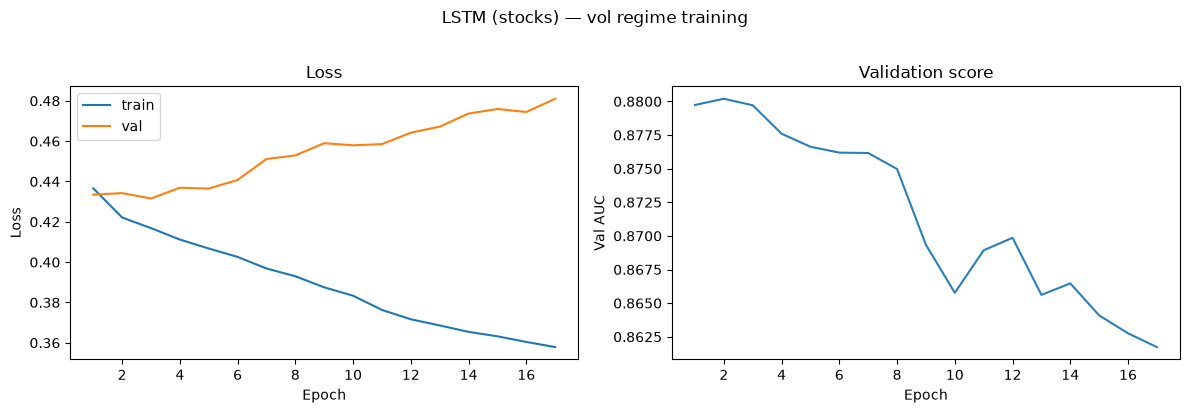

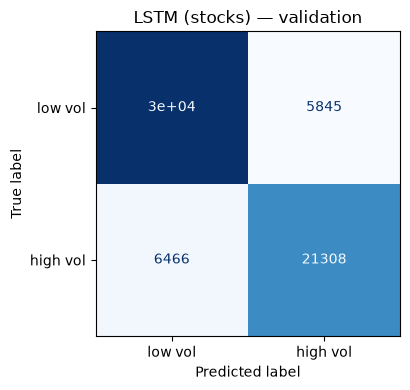

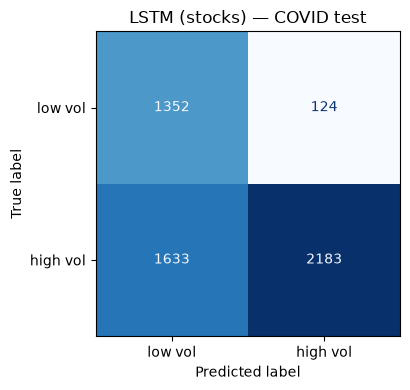

,Model,Val macro-F1,Crisis macro-F1,Val accuracy
0,LSTM (stocks),0.802236,0.659596,0.805753
1,Majority class (train),0.359702,0.218085,0.561772


In [6]:
hist_df = pd.DataFrame(
    {
        "epoch": np.arange(1, len(history.history["loss"]) + 1),
        "train_loss": history.history["loss"],
        "val_loss": history.history["val_loss"],
        "val_score": history.history.get(
            "val_auc",
            history.history.get("val_mae", [0.0]),
        ),
    }
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_df["epoch"], hist_df["train_loss"], label="train")
axes[0].plot(hist_df["epoch"], hist_df["val_loss"], label="val")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(hist_df["epoch"], hist_df["val_score"], color="#2980b9")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Val AUC" if "val_auc" in history.history else "Val score")
axes[1].set_title("Validation score")
fig.suptitle("LSTM (stocks) — vol regime training", y=1.02)
plt.tight_layout()
plt.show()

from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

def plot_confusion(y_true: np.ndarray, y_pred: np.ndarray, title: str) -> None:
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay(
        confusion_matrix(y_true.astype(int), y_pred.astype(int)),
        display_labels=["low vol", "high vol"],
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

plot_confusion(y_val, val_pred, "LSTM (stocks) — validation")
plot_confusion(y_test, test_pred, "LSTM (stocks) — COVID test")

from tf_notebook_utils import classification_metrics

majority_class = int(round(float(np.mean(y_train))))
majority_val = classification_metrics(
    y_val, np.full(len(y_val), majority_class, dtype=np.float32)
)
majority_crisis = classification_metrics(
    y_test, np.full(len(y_test), majority_class, dtype=np.float32)
)

table = pd.DataFrame(
    [
        {
            "Model": "LSTM (stocks)",
            "Val macro-F1": val_macro_f1,
            "Crisis macro-F1": crisis_macro_f1,
            "Val accuracy": val_metrics["accuracy"],
        },
        {
            "Model": "Majority class (train)",
            "Val macro-F1": majority_val["macro_f1"],
            "Crisis macro-F1": majority_crisis["macro_f1"],
            "Val accuracy": majority_val["accuracy"],
        },
    ]
)
display(table)


## 6) Save model and prediction artifacts

Save TensorFlow model files and JSON metrics/predictions for cross-platform comparison.

In [7]:
artifact_stem = f"{ARCHITECTURE}_{JOB_SLUG}_{UNIVERSE}{MODEL_TAG}_tf"
best_model_path = MODELS_DIR / f"{artifact_stem}_best.keras"
final_model_path = MODELS_DIR / f"{artifact_stem}_final.keras"
pred_path = MODELS_DIR / f"{artifact_stem}_predictions.json"

model.save(best_model_path)
model.save(final_model_path)

payload = {
    "job_id": JOB_ID,
    "job_slug": JOB_SLUG,
    "architecture": ARCHITECTURE,
    "universe": UNIVERSE,
    "model": f"{ARCHITECTURE}_{JOB_SLUG}_{UNIVERSE}{MODEL_TAG}_tensorflow",
    "run_mode": RUN_MODE,
    "dataset_tag": DATASET_TAG,
    "n_symbols": bundle.cfg.get("n_symbols"),
    "framework": "tensorflow" if ARCHITECTURE != "xgb" else getattr(model, "backend", "tree"),
    "target_type": bundle.cfg["target_type"],
    "n_features": len(bundle.feature_cols),
    "lookback_days": bundle.cfg["lookback_days"],
    "feature_cols": bundle.feature_cols,
    "best_epoch": best_epoch,
    "best_val_macro_f1": best_val_macro_f1,
    "val_macro_f1": val_macro_f1,
    "val_accuracy": val_metrics["accuracy"],
    "crisis_macro_f1": crisis_macro_f1,
    "crisis_accuracy": crisis_metrics["accuracy"],
    "baseline_comparison": baseline_comparison,
    "train_config": {
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS if ARCHITECTURE != "xgb" else 1,
        "patience": PATIENCE if ARCHITECTURE != "xgb" else 0,
        "lr": LR if ARCHITECTURE != "xgb" else 0.0,
        "loss": "binary_crossentropy",
        "architecture": ARCHITECTURE,
        "device": device_info,
        "sequences_name": sequences_name,
    },
    "history": hist_df.to_dict(orient="records"),
    "predictions": {
        "val": {"y_true": y_val.tolist(), "y_pred": val_pred.tolist(), "y_prob": val_probs.tolist()},
        "test": {"y_true": y_test.tolist(), "y_pred": test_pred.tolist(), "y_prob": test_probs.tolist()},
    },
    "trained_at": datetime.now(timezone.utc).isoformat(),
}

with open(pred_path, "w") as f:
    json.dump(payload, f, indent=2)

print("Saved artifacts:")
print(f"- {best_model_path}")
print(f"- {final_model_path}")
print(f"- {pred_path}")


Saved artifacts:
- /home/friyekekanu/ai-workspace/experiments/stock-prediction/data/models/lstm_vol_regime_stocks_dev200_tf_best.keras
- /home/friyekekanu/ai-workspace/experiments/stock-prediction/data/models/lstm_vol_regime_stocks_dev200_tf_final.keras
- /home/friyekekanu/ai-workspace/experiments/stock-prediction/data/models/lstm_vol_regime_stocks_dev200_tf_predictions.json
